## Step 1: Summary statistics

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

sns.set_style("whitegrid")
df = pd.read_csv("Titanic-Dataset.csv")
df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [2]:
print(df.shape)
df.info()
print(df.isnull().sum())

(891, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype:

In [3]:
display(df.describe())
display(df.describe(include='object'))
print("Median:\n", df.select_dtypes('number').median())
print("Skewness:\n", df.select_dtypes('number').skew())

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


,Name,Sex,Ticket,Cabin,Embarked
count,891,891,891,204,889
unique,891,2,681,147,3
top,"Braund, Mr. Owen Harris",male,347082,G6,S
freq,1,577,7,4,644


Median:
 PassengerId    446.0000
Survived         0.0000
Pclass           3.0000
Age             28.0000
SibSp            0.0000
Parch            0.0000
Fare            14.4542
dtype: float64
Skewness:
 PassengerId    0.000000
Survived       0.478523
Pclass        -0.630548
Age            0.389108
SibSp          3.695352
Parch          2.749117
Fare           4.787317
dtype: float64


## Step 2: Histograms and boxplots

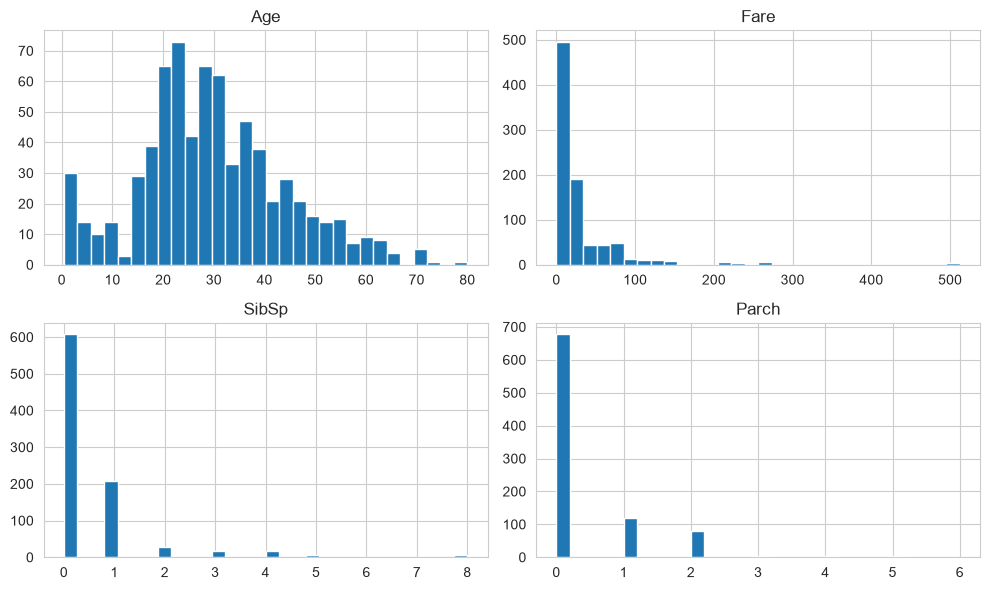

In [4]:
num_cols = ['Age', 'Fare', 'SibSp', 'Parch']
df[num_cols].hist(bins=30, figsize=(10, 6))
plt.tight_layout()
plt.show()

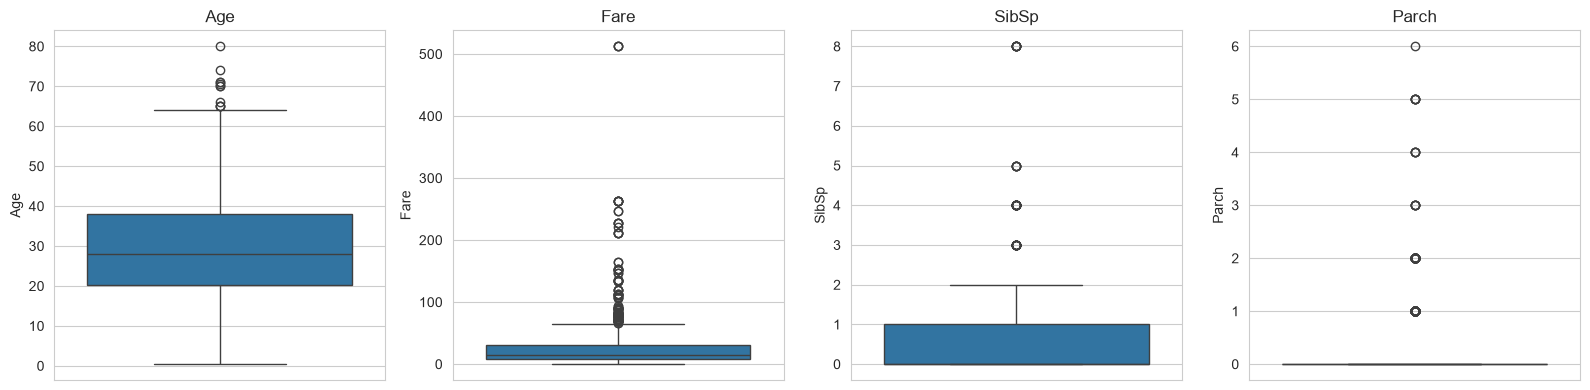

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

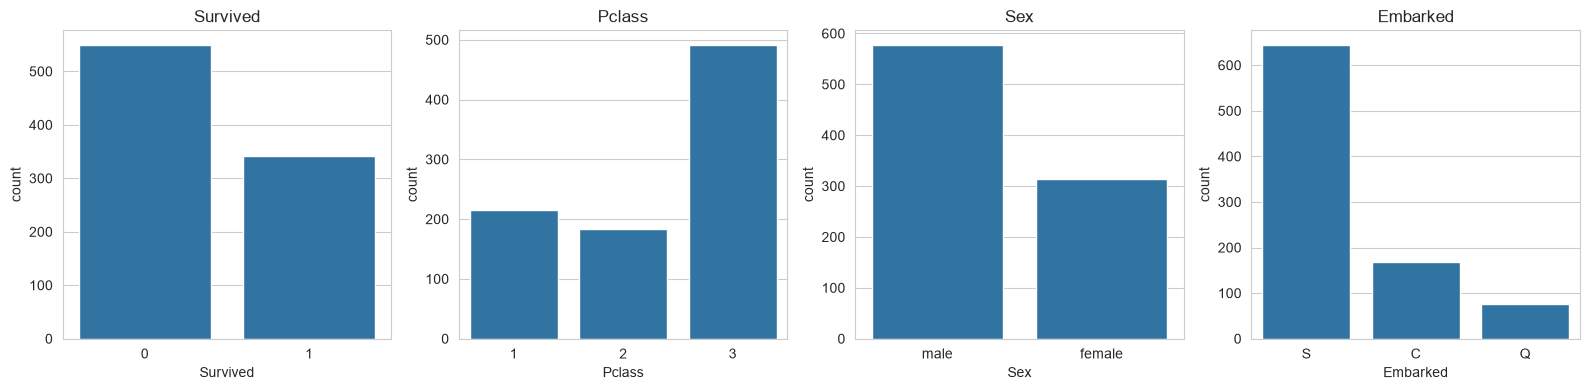

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ['Survived', 'Pclass', 'Sex', 'Embarked']):
    sns.countplot(x=col, data=df, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

## Step 3: Feature relationships

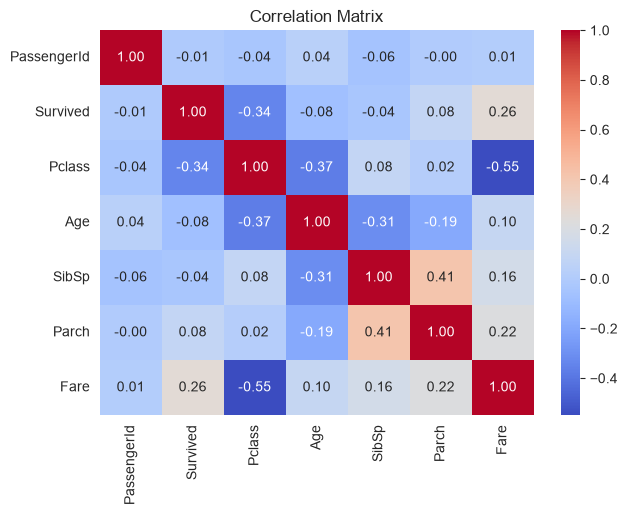

In [7]:
plt.figure(figsize=(7, 5))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()

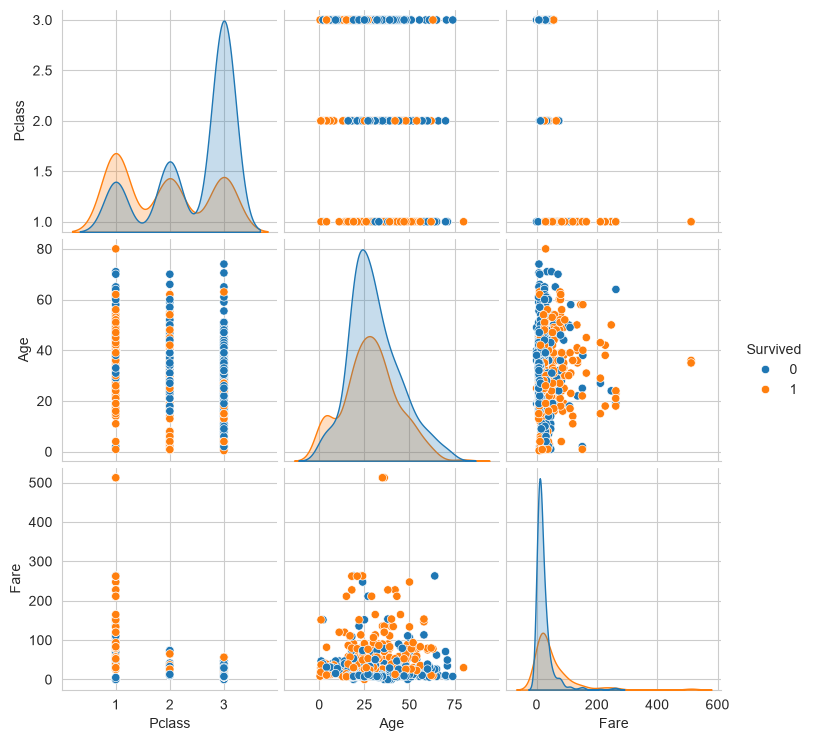

In [8]:
sns.pairplot(df[['Survived', 'Pclass', 'Age', 'Fare']].dropna(), hue='Survived')
plt.show()

## Step 4: Patterns, trends and anomalies

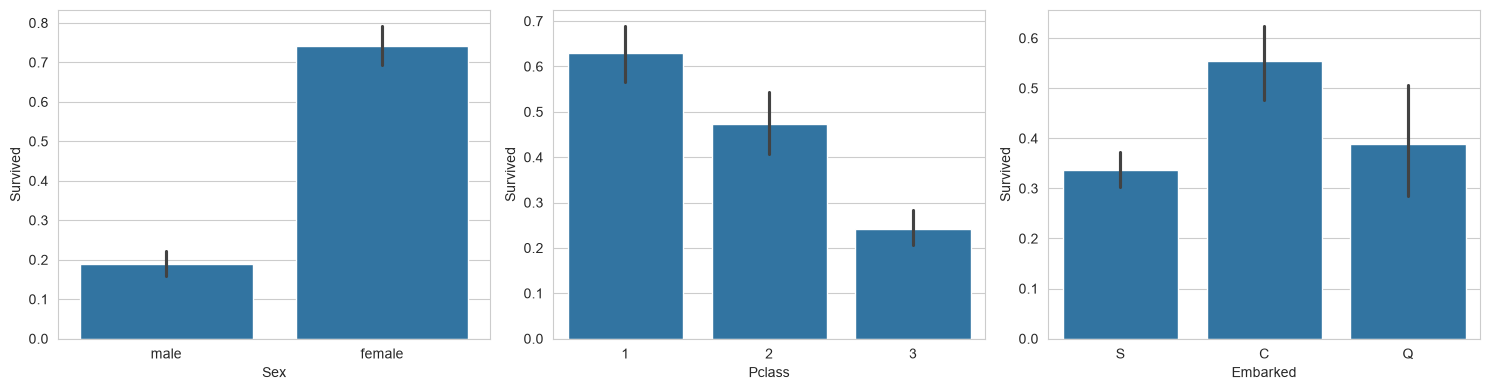

In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.barplot(x='Sex', y='Survived', data=df, ax=axes[0])
sns.barplot(x='Pclass', y='Survived', data=df, ax=axes[1])
sns.barplot(x='Embarked', y='Survived', data=df, ax=axes[2])
plt.tight_layout()
plt.show()

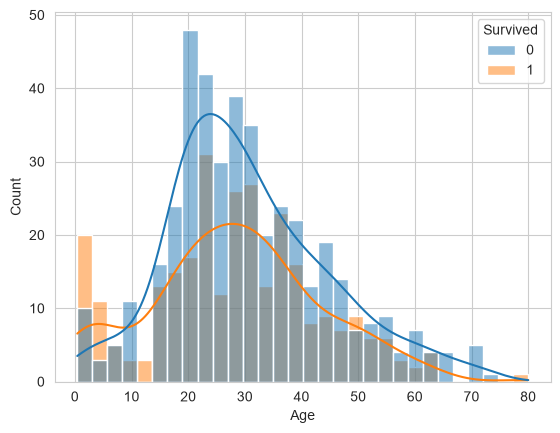

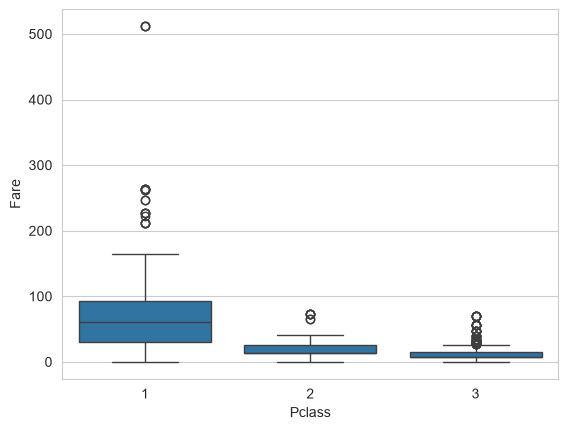

In [10]:
sns.histplot(data=df, x='Age', hue='Survived', kde=True, bins=30)
plt.show()

sns.boxplot(x='Pclass', y='Fare', data=df)
plt.show()

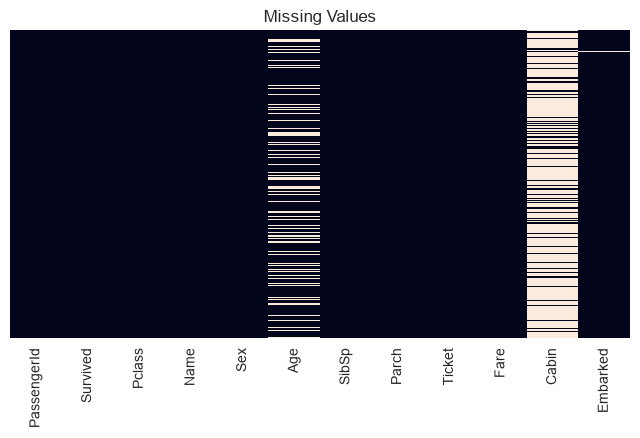

In [11]:
plt.figure(figsize=(8, 4))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title('Missing Values')
plt.show()

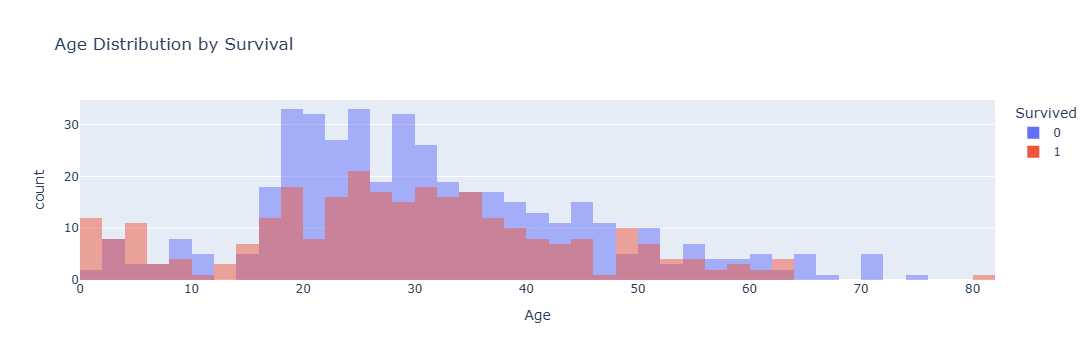

In [12]:
fig = px.histogram(df, x='Age', color='Survived', barmode='overlay',
                   title='Age Distribution by Survival')
fig.show()
fig.write_html("age_survival_plotly.html")

## Step 5: Key Insights

**Summary statistics**
- The dataset has 891 passengers and 12 columns.
- Age has 177 missing values (about 20%), Cabin has 687 (about 77%), and Embarked has 2.
- The average age is about 29.7 years, and most passengers are between 20 and 40.
- About 38% of passengers survived.

**Distributions**
- Fare is heavily right-skewed (skewness about 4.8). Most fares are low, but a few go as high as 512, and the mean (about 32) is much higher than the median (about 14). Age is only slightly skewed (about 0.39).
- Fare also has 15 values of 0, which may be data errors or special tickets.
- SibSp and Parch are mostly 0, meaning most passengers travelled alone.
- Boxplots show many outliers in Fare, and also in Age at the older end.

**Relationships**
- Pclass and Fare have a moderate negative correlation (-0.55), which is the strongest pair. No pair is above 0.7, so multicollinearity is only mild here.
- Pclass and Survived are negatively correlated, so higher class passengers (class 1) survived more.
- SibSp and Parch are positively correlated, since families travel together.
- Fare has a weak positive correlation with Survived.

**Patterns in survival**
- Women survived at a much higher rate than men (about 74% vs 19%).
- 1st class passengers survived more (about 63%) than 3rd class (about 24%).
- Passengers who embarked at Cherbourg (C) survived more than those from Southampton (S).
- Young children had a higher survival rate than other age groups.

**Anomalies and data quality**
- Cabin is too sparse to use directly.
- Age needs imputation before modelling.
- Fare outliers should be handled, for example with a log transform or by capping.

**Conclusion**
Sex, passenger class and age are the most important factors in survival. These features will be the most useful for a prediction model.

In [13]:
print((df['Fare'] == 0).sum())

15
